# MAU TONG QUAT - GIAI DE THI KHAI PHA WEB (CHUONG 2 + CHUONG 3)

Notebook nay KHONG gan cung voi mot de cu the. Muc tieu la lam **khung xuong dung
duoc cho nhieu de khac nhau** cua cung dang bai (thu thap du lieu tu HTML offline
+ tien xu ly/kham pha du lieu van ban tieng Viet), chi can chinh phan **CAU HINH**
o Cell tiep theo va doc cac o **"SO TAY BIEN THE"** truoc moi cau de biet cho nao
co the phai sua nom them.

> Notebook nay duoc chay thu tren bo du lieu cua **De 1** (laptop / khach san) chi
> de minh hoa - khi dung cho de khac, chi can thay du lieu trong `Data/` va chinh
> lai CONFIG, phan lon code ben duoi khong can dong vao.

## Ban do doi chieu voi tai lieu Chuong 2 / Chuong 3

De nho lai co the tra ve dung vi du lien quan khi gap mot cau hoi la:

| Tinh huong | Vi du Chuong 2 / Chuong 3 lien quan |
|---|---|
| Tai HTML truc tiep tu Internet (khong phai file offline) | `Exam21.py`, `Exam26.py` (requests.get) |
| Trich xuat bang regex thay vi BeautifulSoup | `Exam22a.py`, `Exam22b.py`, `Exam23.py` |
| HTML loi/khong chuan can "sua" truoc khi doc | `Exam24a.py`, `Exam24b.py` (html.parser vs html5lib) |
| Trich xuat theo class bang BeautifulSoup | `Exam25a.py`, `Exam25b.py` |
| Thu thap nhieu trang / crawl link theo phan trang | `Exam25c.py`, `Exam27.py`, `Exam28.py` |
| Doc tu RSS feed | `Exam26.py` |
| Bo dau cau bang regex hoac thu vien `string` | `Exam32a.py`, `Exam32b.py` |
| Bo chu so trong van ban | `Exam32c.py` |
| Bo the HTML con sot trong van ban (khac voi Cau 1 - o day la van ban, khong phai trang web) | `Exam32d.py` |
| Doi emoji/emoticon sang chu (thu vien `emot`) | `Exam33.py` (de thi thay bang file `emoji_map.csv` co san) |
| Bo stop word tieng Anh (nltk) hoac tieng Viet (file .txt) | `Exam34a.py`, `Exam34b.py` |
| Tach cau | `Exam35a.py`, `Exam35b.py` |
| Chuan hoa tu viet tat theo tu dien | `Exam36.py` (de thi thay bang file `tu_dien_chuan_hoa.csv`) |
| Sua loi chinh ta tu dong (khong dung trong de thi vi can Internet/model) | `Exam37a.py`, `Exam37b.py` |
| Tach tu tieng Anh (nltk) / tieng Viet (underthesea) | `Exam38a.py`, `Exam38b.py` |
| Thong ke tan suat + wordcloud + bieu do | `Exam310.py` (day chinh la khung cua Cau 2d, 2e) |


## 1. CAU HINH - CHI SUA O DAY KHI DOI SANG DE KHAC

In [1]:
from pathlib import Path
from collections import Counter
import re
import unicodedata

import pandas as pd
from bs4 import BeautifulSoup
from underthesea import word_tokenize
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# ROOT luon la thu muc chua notebook nay (dung Path thay os.path de ghep duong
# dan bang toan tu '/' - de doc, hoat dong tren ca Windows/macOS/Linux)
ROOT = Path.cwd()
CAU1 = ROOT / "Cau1"
CAU2 = ROOT / "Cau2"
CAU1.mkdir(exist_ok=True)
CAU2.mkdir(exist_ok=True)

# ----------------------------------------------------------------------------
# TAT CA THAM SO CO THE PHAI DOI KHI GAP MOT DE KHAC DUOC GOM O DAY.
# Doc ky comment ben canh moi dong truoc khi sua.
# ----------------------------------------------------------------------------
CONFIG = {
    # ---- Cau 1: duong dan du lieu HTML ----
    "html_dir": ROOT / "Data" / "Chuong2" / "pages",   # doi neu de dat ten thu muc khac (vd "Data/Chuong 2" khong co "pages")
    "html_files": ["page1.html", "page2.html"],          # them/bot ten file neu de co nhieu/it trang hon

    # CSS selector cua 1 "khoi san pham". Neu HTML dung the/class khac (vd
    # <div class="item">...) thi doi chuoi nay, khong can sua code ben duoi.
    "card_selector": "article.product-card",

    # Anh xa: ten cot ket qua -> CSS selector lay du lieu trong 1 khoi san pham.
    # Them/bot/doi selector neu de dat ten class khac (vd ".gia-goc" thay vi ".list-price").
    "field_selectors": {
        "ten_sp": ".product-name",
        "gia_goc": ".list-price",
        "gia_ban": ".sale-price",
        "khuyen_mai": ".promotion",   # truong nay co the thieu o mot so san pham -> code da xu ly an toan
    },

    # So dong ky vong sau khi gop tat ca file HTML (dung de assert kiem tra tu dong).
    # Neu de KHONG noi ro so luong, doi thanh None de bo qua kiem tra nay.
    "so_dong_ky_vong_cau1": 8,

    "ten_file_tho": "san_pham_tho.csv",
    "ten_file_sach": "san_pham_sach.csv",
    "so_chu_so_lam_tron_ty_le_giam": 2,   # de co the yeu cau lam tron khac 2 chu so

    # ---- Cau 2: duong dan du lieu van ban ----
    "chuong3_dir": ROOT / "Data" / "Chuong3",
    "reviews_file": "reviews_raw.csv",
    "cot_id": "id",            # doi neu de dat ten cot khac (vd "ma_review")
    "cot_noi_dung": "review",  # doi neu de dat ten cot khac (vd "noi_dung", "comment")

    # Cac file ho tro nay CO THE KHONG DUOC DE CUNG CAP -> code se tu kiem tra
    # ton tai, neu thieu se dung dict/rong tuong ung va khong bi loi.
    "emoji_file": "emoji_map.csv",
    "tudien_file": "tu_dien_chuan_hoa.csv",
    "stopwords_file": "stopwords.txt",

    # Bat/tat tung buoc lam sach o Cau 2a - huu ich khi de yeu cau thu tu
    # hoac danh sach buoc khac (vd de khong yeu cau xoa chu so).
    "buoc1_xoa_the_html": True,
    "buoc1_ha_chu_thuong": True,
    "buoc1_xoa_url": True,
    "buoc1_xoa_chu_so": True,

    "top_n": 10,   # doi neu de yeu cau top 5, top 20, ...
}

print("Thu muc lam viec:", ROOT)
print("CONFIG da san sang, xem chi tiet o cell tren.")

Thu muc lam viec: D:\Workspace\KPW\class\GK\1_detk
CONFIG da san sang, xem chi tiet o cell tren.


## Cau 1a - Doc 1 file HTML, in ten san pham

### So tay bien the
- **De khong cho file offline ma bat tai truc tiep tu mang** -> thay
  `Path.read_text()` bang `requests.get(url).text` (xem `Exam21.py`, `Exam26.py`).
  Luc do can nho: doc de co cam Internet hay khong truoc khi lam.
- **HTML dung the/class khac** (vd `<div class="item">` thay vi
  `<article class="product-card">`) -> chi doi `CONFIG["card_selector"]`, code
  ben duoi khong doi.
- **De yeu cau dung `find_all`/`find` thay vi `select`/`select_one`** (cach viet
  trong slide, vd `Exam25a.py`) -> ve mat ket qua 2 cach tuong duong; `select`
  dung cu phap CSS selector nen ngan hon khi loc theo class.

In [2]:
def doc_1_file_html(ten_file):
    duong_dan = CONFIG["html_dir"] / ten_file
    html = duong_dan.read_text(encoding="utf-8")
    # html5lib mo phong dung cach trinh duyet doc HTML, tu sua the thieu/loi
    # (Exam24b.py) - an toan hon html.parser (Exam24a.py) voi HTML "khong sach".
    return BeautifulSoup(html, "html5lib")


soup_trang_1 = doc_1_file_html(CONFIG["html_files"][0])

# In ten cua tung san pham trong trang dau tien (dung dung field dau tien
# trong field_selectors thay vi hardcode "ten_sp" de code linh hoat hon)
ten_field, ten_selector = next(iter(CONFIG["field_selectors"].items()))
for card in soup_trang_1.select(CONFIG["card_selector"]):
    print(card.select_one(ten_selector).get_text(strip=True))

# 📌 CACH THEO SLIDE (Exam25a.py) - chi tham khao:
# TenSP = soup.find_all("h3", class_="product-name")
# for name in TenSP:
#     print(name.text.strip())

Laptop Alpha 14
Laptop Beta Air
Laptop Gamma Book
Laptop Delta Mini


## Cau 1b - Boc tach tat ca san pham trong nhieu file HTML

### So tay bien the
- **So luong truong can lay khac 4** -> chi can them/bot key trong
  `CONFIG["field_selectors"]`, vong lap `for ten_cot, selector in ...items()`
  ben duoi tu dong chay dung voi so luong truong moi.
- **Mot so san pham thieu 1 truong bat ky** (khong chi rieng khuyen mai) -> ham
  `lay_text_an_toan` da tra ve chuoi rong cho MOI truong bi thieu, khong chi
  rieng khuyen_mai.
- **BAY THUONG GAP (giai thich trong bai mau 4_DoHuuHau)**: neu dung
  `find_all()` de lay rieng tung danh sach (vd danh sach tat ca `.product-name`,
  danh sach tat ca `.promotion`) roi ghep theo chi so `i`, thi khi co san pham
  thieu the khuyen mai, CAC SAN PHAM SAU DO SE BI LECH DONG (vi danh sach
  promotion ngan hon danh sach ten). Cach an toan la duyet TUNG the card mot,
  roi trong moi card moi tim field - dung nhu code ben duoi.

In [3]:
def lay_text_an_toan(card, selector):
    """Tra ve rong ('') neu the khong ton tai, thay vi loi AttributeError."""
    the = card.select_one(selector)
    return the.get_text(" ", strip=True) if the is not None else ""


danh_sach_sp = []
for ten_file in CONFIG["html_files"]:
    soup = doc_1_file_html(ten_file)
    for card in soup.select(CONFIG["card_selector"]):
        dong = {
            ten_cot: lay_text_an_toan(card, selector)
            for ten_cot, selector in CONFIG["field_selectors"].items()
        }
        danh_sach_sp.append(dong)

df_tho = pd.DataFrame(danh_sach_sp)

if CONFIG["so_dong_ky_vong_cau1"] is not None:
    assert len(df_tho) == CONFIG["so_dong_ky_vong_cau1"], (
        f"Ky vong {CONFIG['so_dong_ky_vong_cau1']} dong nhung nhan duoc {len(df_tho)}. "
        "Kiem tra lai CONFIG['card_selector'] hoac CONFIG['html_files']."
    )

duong_dan_tho = CAU1 / CONFIG["ten_file_tho"]
df_tho.to_csv(duong_dan_tho, index=False, encoding="utf-8")
print("Da luu:", duong_dan_tho, "-", len(df_tho), "dong")
df_tho

Da luu: D:\Workspace\KPW\class\GK\1_detk\Cau1\san_pham_tho.csv - 8 dong


,ten_sp,gia_goc,gia_ban,khuyen_mai
0,Laptop Alpha 14,21.990.000 đ,18.990.000 đ,Tặng chuột không dây
1,Laptop Beta Air,17.500.000 đ,16.990.000 đ,Giảm thêm 300.000 đ qua mã WEB
2,Laptop Gamma Book,25.000.000 đ,21.250.000 đ,Trả góp 0 phần trăm
3,Laptop Delta Mini,14.200.000 đ,14.200.000 đ,
4,Laptop Epsilon Pro,32.490.000 đ,27.990.000 đ,Tặng balo và chuột
5,Laptop Zeta Office,19.900.000 đ,18.500.000 đ,Bảo hành 24 tháng
6,Laptop Eta Gaming,35.750.000 đ,28.600.000 đ,Tặng tai nghe gaming
7,Laptop Theta Student,12.800.000 đ,11.990.000 đ,Giảm giá sinh viên


## Cau 1c - Lam sach gia va tinh ty le giam

### So tay bien the
- **Dinh dang gia khac** (vd gia kieu My `"1,299.99"` - dau `,` la phan cach
  hang nghin, dau `.` la thap phan, KHONG giong gia VND `"21.990.000 d"` ma dau
  `.` la phan cach hang nghin) -> phai doi ham `doi_sang_so` cho phu hop dinh
  dang, KHONG the dung chung mot regex `[^\d]` cho ca 2 truong hop nay (regex
  do se lam mat phan thap phan cua gia USD). Voi de VND thi cach lam ben duoi
  van dung.
- **De hoi thap ty le giam khac 2 chu so** -> doi
  `CONFIG["so_chu_so_lam_tron_ty_le_giam"]`.
- **Luon doc lai file `*_tho.csv` bang `keep_default_na=False`** khi cot co the
  chua chuoi rong, vi mac dinh pandas se doi chuoi rong thanh `NaN`, lam hong
  buoc `.replace("", ...)` phia duoi.

In [4]:
# Doc lai dung file cua y truoc, giu chuoi rong la "" thay vi NaN
df_tho = pd.read_csv(duong_dan_tho, encoding="utf-8", keep_default_na=False)

def doi_sang_so_nguyen_vnd(chuoi_gia):
    """Vi du: '21.990.000 d' -> 21990000. Chi dung cho dinh dang VND
    (dau . la phan cach hang nghin). Neu de dung dinh dang khac, sua ham nay."""
    chi_so = re.sub(r"\D", "", str(chuoi_gia))   # \D = khong phai chu so
    return int(chi_so) if chi_so else 0


df_sach = df_tho.copy()
df_sach["gia_goc_vnd"] = df_sach["gia_goc"].apply(doi_sang_so_nguyen_vnd)
df_sach["gia_ban_vnd"] = df_sach["gia_ban"].apply(doi_sang_so_nguyen_vnd)
df_sach["khuyen_mai"] = df_sach["khuyen_mai"].replace("", "Khong co khuyen mai")
df_sach["ty_le_giam"] = (
    (df_sach["gia_goc_vnd"] - df_sach["gia_ban_vnd"]) / df_sach["gia_goc_vnd"] * 100
).round(CONFIG["so_chu_so_lam_tron_ty_le_giam"])

df_sach = df_sach[["ten_sp", "gia_goc_vnd", "gia_ban_vnd", "khuyen_mai", "ty_le_giam"]]

duong_dan_sach = CAU1 / CONFIG["ten_file_sach"]
df_sach.to_csv(duong_dan_sach, index=False, encoding="utf-8")
print("Da luu:", duong_dan_sach)
df_sach

Da luu: D:\Workspace\KPW\class\GK\1_detk\Cau1\san_pham_sach.csv


,ten_sp,gia_goc_vnd,gia_ban_vnd,khuyen_mai,ty_le_giam
0,Laptop Alpha 14,21990000,18990000,Tặng chuột không dây,13.64
1,Laptop Beta Air,17500000,16990000,Giảm thêm 300.000 đ qua mã WEB,2.91
2,Laptop Gamma Book,25000000,21250000,Trả góp 0 phần trăm,15.00
3,Laptop Delta Mini,14200000,14200000,Khong co khuyen mai,0.00
4,Laptop Epsilon Pro,32490000,27990000,Tặng balo và chuột,13.85
5,Laptop Zeta Office,19900000,18500000,Bảo hành 24 tháng,7.04
6,Laptop Eta Gaming,35750000,28600000,Tặng tai nghe gaming,20.00
7,Laptop Theta Student,12800000,11990000,Giảm giá sinh viên,6.33


## Cau 2 - Doc du lieu van ban va cac tep ho tro

### So tay bien the
- **De co the KHONG cung cap `emoji_map.csv` hoac `tu_dien_chuan_hoa.csv`**
  (mot so de rut gon chi con stopwords.txt) -> code kiem tra `Path.exists()`
  truoc, neu thieu se dung dict rong va bo qua buoc thay the tuong ung, KHONG
  bi loi `FileNotFoundError`.
- **Ten cot trong `reviews_raw.csv` co the khac `id`/`review`** -> doi
  `CONFIG["cot_id"]` / `CONFIG["cot_noi_dung"]`, khong can sua code phia duoi.

In [5]:
duong_dan_reviews = CONFIG["chuong3_dir"] / CONFIG["reviews_file"]
df = pd.read_csv(duong_dan_reviews, encoding="utf-8", keep_default_na=False)
df = df.rename(columns={CONFIG["cot_id"]: "id", CONFIG["cot_noi_dung"]: "review"})


def doc_bang_tra_an_toan(ten_file, cot_key, cot_value):
    """Doc file CSV 2 cot thanh dict; tra ve dict rong neu file khong ton tai."""
    duong_dan = CONFIG["chuong3_dir"] / ten_file
    if not duong_dan.exists():
        print(f"[Bo qua] Khong tim thay {ten_file} - dung bang tra rong.")
        return {}
    bang = pd.read_csv(duong_dan, encoding="utf-8")
    return dict(zip(bang[cot_key], bang[cot_value]))


emoji_map = doc_bang_tra_an_toan(CONFIG["emoji_file"], "ky_hieu", "van_ban")
tu_dien = doc_bang_tra_an_toan(CONFIG["tudien_file"], "tu_goc", "tu_chuan")

duong_dan_stop = CONFIG["chuong3_dir"] / CONFIG["stopwords_file"]
if duong_dan_stop.exists():
    danh_sach_stop_goc = [d.strip() for d in duong_dan_stop.read_text(encoding="utf-8").splitlines() if d.strip()]
else:
    print("[Bo qua] Khong tim thay stopwords.txt - khong loai stop word nao.")
    danh_sach_stop_goc = []

print("So dong review:", len(df))
print("So ky hieu emoji:", len(emoji_map), "| So tu can chuan hoa:", len(tu_dien), "| So stop word:", len(danh_sach_stop_goc))
df.head()

So dong review: 10
So ky hieu emoji: 4 | So tu can chuan hoa: 7 | So stop word: 19


,id,review
0,RV01,<p>KS 5 sao!!! Nhân viên rất thân thiện 😍. Xem...
1,RV02,"Phòng sạch, view biển đẹp :) nhưng wifi yếu 2 ..."
2,RV03,"Dịch vụ ok, đồ ăn ngon; giá 1.250.000đ/đêm hơi..."
3,RV04,"Tôi đặt phòng qua www.example.com, check-in nh..."
4,RV05,"Nhân viên lễ tân nhiệt tình, nhưng phòng hơi n..."


## Cau 2a - Buoc 1: lam sach so bo

### So tay bien the
- **De co the khong yeu cau xoa het ca 4 loai (HTML/URL/so/hoa-thuong)**, hoac
  yeu cau them buoc khac (vd xoa emoji ngay tu buoc nay) -> dung 4 cong tac
  `CONFIG["buoc1_..."]` de bat/tat tung buoc ma khong can sua ham.
- **Dung BeautifulSoup thay vi regex de xoa the HTML**: `get_text(" ")` xu ly
  dung ca truong hop the long nhau, thuoc tinh chua ky tu `>` ben trong chuoi -
  cac tinh huong ma regex don gian `<[^>]+>` co the xu ly sai.

In [6]:
def buoc1_lam_sach_so_bo(text):
    text = str(text)

    if CONFIG["buoc1_xoa_the_html"]:
        # get_text(" ") vua bo the HTML, vua chen khoang trang giua cac doan
        # noi dung de tranh 2 tu o 2 ben the bi dinh lien vao nhau.
        text = BeautifulSoup(text, "html.parser").get_text(" ")

    if CONFIG["buoc1_ha_chu_thuong"]:
        text = text.lower()

    if CONFIG["buoc1_xoa_url"]:
        # Phai xoa URL TRUOC KHI xoa chu so (buoc duoi), vi URL thuong chua so
        # (vd 'menu/1'); neu xoa so truoc se de lai rac dang 'menu/'.
        text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    if CONFIG["buoc1_xoa_chu_so"]:
        text = re.sub(r"\d+", " ", text)

    return " ".join(text.split())   # chuan hoa khoang trang: gop nhieu space thanh 1


df_buoc1 = df[["id"]].copy()
df_buoc1["review_buoc1"] = df["review"].apply(buoc1_lam_sach_so_bo)

duong_dan_buoc1 = CAU2 / "buoc1.csv"
df_buoc1.to_csv(duong_dan_buoc1, index=False, encoding="utf-8")
df_buoc1

,id,review_buoc1
0,RV01,ks sao!!! nhân viên rất thân thiện 😍. xem thêm...
1,RV02,"phòng sạch, view biển đẹp :) nhưng wifi yếu ng..."
2,RV03,"dịch vụ ok, đồ ăn ngon; giá . . đ/đêm hơi cao."
3,RV04,tôi đặt phòng qua check-in nhanh!!!
4,RV05,"nhân viên lễ tân nhiệt tình, nhưng phòng hơi n..."
5,RV06,"ks gần biển, vị trí tiện, sẽ quay lại :d"
6,RV07,"điều hòa hỏng, phòng nóng độ, xử lý chậm 😒"
7,RV08,"buffet sáng đa dạng, trẻ em rất thích!"
8,RV09,"pview đẹp nhưng tolet chưa sạch, tôi kg hài lòng."
9,RV10,"nội thất mới, yên tĩnh, đáng tiền %."


## Cau 2b - Buoc 2: doi emoji, chuan hoa tu, xoa dau cau

### So tay bien the (day la buoc de mac loi ngam nhat)
1. **Lech chu hoa/thuong**: neu buoc 1 da ha chu thuong toan bo van ban, mot
   emoticon co chu hoa trong `emoji_map.csv` (vd `:D`) se khong con khop nguyen
   dang. Code duoi luon so khop theo dang **khong phan biet hoa/thuong**
   (`symbol.lower()`) de an toan trong moi truong hop.
2. **Tu ghep boi dau gach noi** (vd `check-in`): can noi 2 ky tu chu quanh dau
   `-` truoc khi tra tu dien, neu khong `check-in` se khong khop voi khoa
   `checkin`. Dung `(?<=\w)-(?=\w)` (lookaround, khong "an" ky tu xung quanh)
   thay vi `(\w)-(\w) -> \1\2` de tranh loi khi co nhieu dau `-` lien tiep.
3. **Thay nham vao giua tu khac**: luon dung ranh gioi tu khi tra tu dien/emoji
   dai hon 1 ky tu, va **uu tien thay ky hieu/tu DAI HON truoc** (sap xep giam
   dan theo do dai) de tranh mot chuoi ngan bi khop nham truoc khi chuoi dai
   hon chua no kip duoc xu ly.
4. **Thu tu thay the va xoa dau cau**: phai thay emoji/tu dien XONG roi moi xoa
   dau cau, vi ban than cac ky hieu (vd `:)`, `:D`) chua dau cau.

In [7]:
df_buoc1 = pd.read_csv(duong_dan_buoc1, encoding="utf-8", keep_default_na=False)

def thay_nguyen_tu(text, tu_cu, tu_moi):
    """Thay tu_cu bang tu_moi, chi khi tu_cu la 1 tu doc lap (co ranh gioi tu)."""
    mau = rf"(?<!\w){re.escape(tu_cu)}(?!\w)"
    return re.sub(mau, tu_moi, text)


def buoc2_chuan_hoa(text):
    # (1) Thay emoji/emoticon truoc, so khop khong phan biet hoa/thuong,
    #     uu tien ky hieu dai hon de tranh khop nham 1 phan cua ky hieu dai.
    for ky_hieu, nghia in sorted(emoji_map.items(), key=lambda kv: -len(str(kv[0]))):
        text = text.replace(str(ky_hieu).lower(), f" {nghia} ")

    # (2) Noi lien 2 ky tu chu bi ngan cach boi dau gach noi (vd check-in -> checkin)
    text = re.sub(r"(?<=\w)-(?=\w)", "", text)

    # (3) Thay tu viet tat/sai chinh ta theo tu dien, tu dai hon xu ly truoc
    for tu_goc, tu_chuan in sorted(tu_dien.items(), key=lambda kv: -len(str(kv[0]))):
        text = thay_nguyen_tu(text, str(tu_goc), str(tu_chuan))

    # (4) Xoa dau cau con lai (giu chu+so+khoang trang, ho tro Unicode tieng Viet)
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)

    return " ".join(text.split())


df_buoc2 = df_buoc1[["id"]].copy()
df_buoc2["review_buoc2"] = df_buoc1["review_buoc1"].apply(buoc2_chuan_hoa)

duong_dan_buoc2 = CAU2 / "buoc2.csv"
df_buoc2.to_csv(duong_dan_buoc2, index=False, encoding="utf-8")
df_buoc2

,id,review_buoc2
0,RV01,khach san sao nhân viên rất thân thiện yeu_thi...
1,RV02,phòng sạch view biển đẹp vui_ve nhưng wi fi yế...
2,RV03,dịch vụ tot đồ ăn ngon giá đ đêm hơi cao
3,RV04,tôi đặt phòng qua nhan phong nhanh
4,RV05,nhân viên lễ tân nhiệt tình nhưng phòng hơi nhỏ
5,RV06,khach san gần biển vị trí tiện sẽ quay lại cuo...
6,RV07,điều hòa hỏng phòng nóng độ xử lý chậm khong_h...
7,RV08,buffet sáng đa dạng trẻ em rất thích
8,RV09,phong đẹp nhưng toilet chưa sạch tôi khong hài...
9,RV10,nội thất mới yên tĩnh đáng tiền


## Cau 2c - Buoc 3: tach tu tieng Viet + loai stop word

### So tay bien the
- **QUAN TRONG NHAT: stopwords.txt co the o dang CO DAU hoac KHONG DAU tuy
  de** (2 de da lam deu dung dang khong dau, nhung khong chac de khac cung
  vay). Code duoi **tu dong nhan dien**: neu trong file stopword khong co bat
  ky ky tu dau tieng Viet nao (khi tach NFD khong con dau to hop `Mn`), suy ra
  file dang KHONG DAU va se bo dau token truoc khi so sanh; nguoc lai so sanh
  truc tiep (khong bo dau).
- **Gioi han cua viec bo dau**: cac tu khac nghia nhung giong nhau khi bo dau
  se bi dam vao nhau, vi du `cho` (stop word) va `chỗ` (tu co nghia) deu thanh
  `cho`, hoac `hoi` (tu `hơi`) va `hỏi` deu thanh `hoi`. Day la gioi han cua du
  lieu dau vao (stopwords.txt khong dau), khong phai loi code - can neu ro
  trong bao cao/nhan xet neu phat hien truong hop nay trong ket qua thuc te,
  KHONG tu y sua tay ket qua de "cho dep".
- **De co the yeu cau giu ca cau (khong tach tu)** hoac dung thu vien tach tu
  khac (`pyvi`, `vncorenlp`) thay vi `underthesea` -> chi doi ham
  `tach_tu_don_le`, phan loai stop word phia duoi khong doi.

In [8]:
df_buoc2 = pd.read_csv(duong_dan_buoc2, encoding="utf-8", keep_default_na=False)

def bo_dau(chuoi):
    # Vi du: 'nhưng' -> 'nhung'. Dung unicodedata, thu vien chuan cua Python.
    chuoi = unicodedata.normalize("NFD", chuoi)
    chuoi = "".join(c for c in chuoi if unicodedata.category(c) != "Mn")
    return chuoi.replace("đ", "d").replace("Đ", "D")


def stopwords_dang_khong_dau(danh_sach):
    # Tu dong nhan dien: neu khong co tu nao trong danh sach bi doi khi bo_dau(),
    # tuc la ban than file da o dang khong dau.
    if not danh_sach:
        return True
    return all(bo_dau(tu) == tu for tu in danh_sach)


stop_khong_dau = stopwords_dang_khong_dau(danh_sach_stop_goc)
stop_words = set(danh_sach_stop_goc)
print("Stopwords.txt duoc nhan dien la dang:", "KHONG DAU" if stop_khong_dau else "CO DAU")


def tach_tu_don_le(text):
    # underthesea tra ve chuoi da tach tu, tu ghep noi boi dau gach duoi '_'
    return word_tokenize(text, format="text").split()


def buoc3_tach_tu_va_loai_stopword(text):
    tokens = tach_tu_don_le(text)
    con_lai = []
    for tu in tokens:
        khoa_so_sanh = bo_dau(tu) if stop_khong_dau else tu
        if khoa_so_sanh not in stop_words:
            con_lai.append(tu)
    return " ".join(con_lai)


df_buoc3 = df_buoc2[["id"]].copy()
df_buoc3["tokens"] = df_buoc2["review_buoc2"].apply(buoc3_tach_tu_va_loai_stopword)

duong_dan_buoc3 = CAU2 / "buoc3.csv"
df_buoc3.to_csv(duong_dan_buoc3, index=False, encoding="utf-8")
df_buoc3

Stopwords.txt duoc nhan dien la dang: KHONG DAU


,id,tokens
0,RV01,khach san_sao nhân_viên thân_thiện yeu_thich xem
1,RV02,phòng sạch view biển đẹp vui_ve wi fi yếu
2,RV03,dịch_vụ tot đồ_ăn ngon giá đ cao
3,RV04,đặt phòng nhan_phong nhanh
4,RV05,nhân_viên lễ_tân nhiệt_tình phòng nhỏ
5,RV06,khach san gần biển vị_trí tiện quay cuoi_lon
6,RV07,điều hòa hỏng phòng nóng_độ xử_lý chậm khong_h...
7,RV08,buffet sáng đa_dạng trẻ_em thích
8,RV09,phong_đẹp toilet sạch khong hài_lòng
9,RV10,nội_thất mới yên_tĩnh đáng tiền


## Cau 2d - Buoc 4: thong ke tan suat unigram

### So tay bien the
- **Tieu chi sap xep co the khac** (vd de yeu cau tang dan theo tan suat, hoac
  giam dan theo alphabet khi bang nhau) -> chi doi dau `-` truoc `kv[1]`/`kv[0]`
  trong `key=lambda kv: (-kv[1], kv[0])`.
- **De co the yeu cau loai token 1 ky tu hoac token toan chu so con sot** ->
  them dieu kien loc truoc khi dem, vi du
  `[t for t in tat_ca_token if len(t) > 1]`.

In [9]:
df_buoc3 = pd.read_csv(duong_dan_buoc3, encoding="utf-8", keep_default_na=False)

tat_ca_token = " ".join(df_buoc3["tokens"]).split()
dem_tan_suat = Counter(tat_ca_token)

# -kv[1]: tan suat GIAM dan | kv[0]: token TANG dan (alphabet) khi tan suat bang nhau
top_n = sorted(dem_tan_suat.items(), key=lambda kv: (-kv[1], kv[0]))[: CONFIG["top_n"]]

df_top_n = pd.DataFrame(top_n, columns=["token", "tan_suat"])
duong_dan_top_n = CAU2 / f"tan_suat_top{CONFIG['top_n']}.csv"
df_top_n.to_csv(duong_dan_top_n, index=False, encoding="utf-8")
df_top_n

,token,tan_suat
0,phòng,4
1,biển,2
2,khach,2
3,nhân_viên,2
4,sạch,2
5,buffet,1
6,cao,1
7,chậm,1
8,cuoi_lon,1
9,dịch_vụ,1


## Cau 2e - Bieu do, wordcloud va nhan xet

### So tay bien the
- **May cham bai co the khong co font Arial/Windows** -> code tu do tim, neu
  khong thay se in canh bao va dung font mac dinh thay vi bi loi dung chuong
  trinh.
- **`collocations=False`** duoc dat cho WordCloud de thu vien khong tu gop 2
  token rieng biet thanh 1 cum (bigram) - vi ban than token cua ta da duoc
  underthesea gop san bang dau `_` khi can, khong muon WordCloud gop them lan
  nua theo cach rieng cua no.
- **Nhan xet duoc sinh TU DONG tu ket qua thuc te** (khong go cung ten token)
  de khi doi Data sang de khac, cau nhan xet van dung theo so lieu moi ma
  khong can sua tay - day la diem quan trong nhat cua ban template nay so voi
  2 bai lam De 1/De 2 (o do nhan xet da duoc go san theo ket qua co dinh).

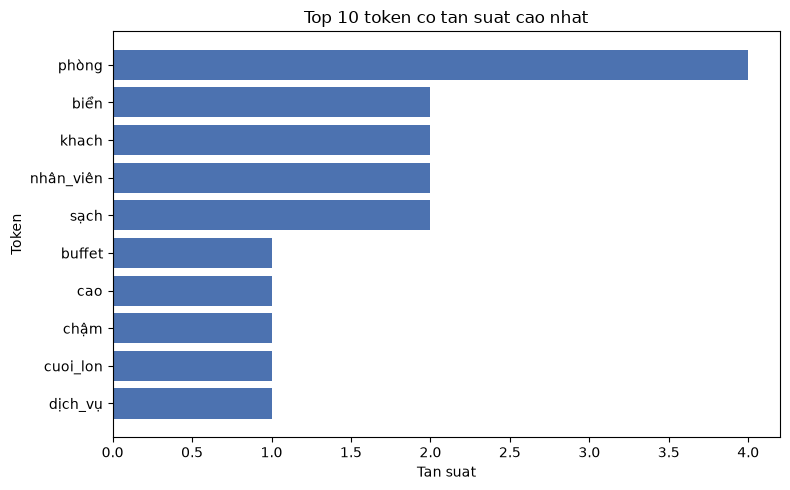

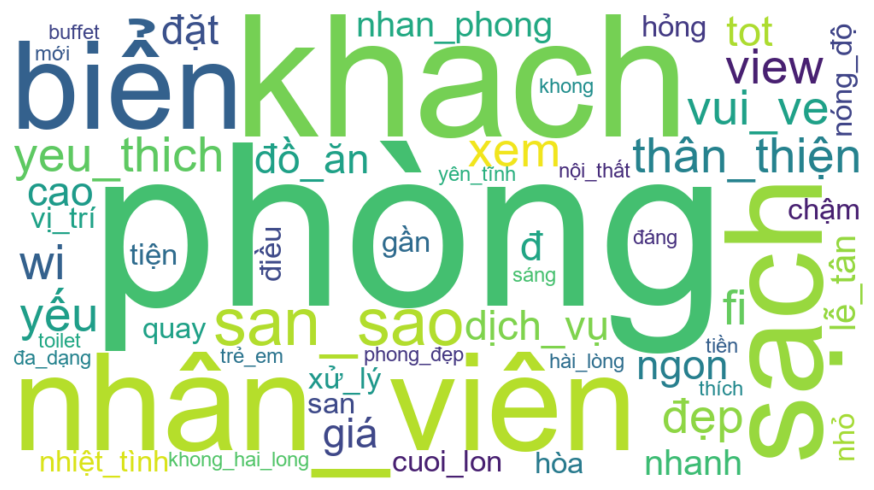

In [10]:
# --- Bieu do cot ngang ---
du_lieu_ve = df_top_n.iloc[::-1]   # dao nguoc de token tan suat cao nhat len tren cung
plt.figure(figsize=(8, 5))
plt.barh(du_lieu_ve["token"], du_lieu_ve["tan_suat"], color="#4C72B0")
plt.xlabel("Tan suat")
plt.ylabel("Token")
plt.title(f"Top {CONFIG['top_n']} token co tan suat cao nhat")
plt.tight_layout()
plt.savefig(CAU2 / "bieu_do_top10.png", dpi=150)
plt.show()

# --- WordCloud ---
duong_dan_font_uu_tien = Path(r"C:\Windows\Fonts\arial.ttf")
if duong_dan_font_uu_tien.exists():
    font_path = str(duong_dan_font_uu_tien)
else:
    print("Khong tim thay font Arial, dung font mac dinh cua WordCloud "
          "(co the bi mat dau tieng Viet khi hien thi).")
    font_path = None

wc = WordCloud(
    width=1000, height=550, background_color="white",
    font_path=font_path, collocations=False,
).generate_from_frequencies(dem_tan_suat)

plt.figure(figsize=(9, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.tight_layout()
plt.savefig(CAU2 / "wordcloud.png", dpi=150)
plt.show()

In [11]:
# --- Sinh nhan xet TU DONG tu ket qua thuc te (khong go cung ten token) ---
top1_token, top1_tan_suat = df_top_n.iloc[0][["token", "tan_suat"]]
tong_tan_suat_top_n = int(df_top_n["tan_suat"].sum())

# Lay toi da 3 token dung sau top 1 de neu trong nhan xet thu 2 (neu du du lieu)
cac_token_ke_tiep = df_top_n.iloc[1:4]
mo_ta_ke_tiep = ", ".join(
    f"'{r.token}' ({r.tan_suat} lan)" for r in cac_token_ke_tiep.itertuples()
)

nhan_xet = (
    f"Nhan xet 1: Token '{top1_token}' co tan suat cao nhat (bang {top1_tan_suat} "
    f"lan), cho thay day la chu de/tu khoa duoc nhac toi nhieu nhat trong cac "
    f"danh gia.\n\n"
    f"Nhan xet 2: Cac token dung ngay sau la {mo_ta_ke_tiep}, cho thay day la "
    f"nhung khia canh khac cung duoc nguoi dung quan tam ben canh chu de chinh "
    f"o Nhan xet 1.\n\n"
    f"(Nhan xet duoc sinh tu dong tu file {duong_dan_top_n.name} - khi doi du "
    f"lieu/de bai, chi can chay lai toan bo notebook, khong can sua tay phan nay.)"
)

(CAU2 / "nhan_xet.txt").write_text(nhan_xet.strip() + "\n", encoding="utf-8")
print(nhan_xet)

Nhan xet 1: Token 'phòng' co tan suat cao nhat (bang 4 lan), cho thay day la chu de/tu khoa duoc nhac toi nhieu nhat trong cac danh gia.

Nhan xet 2: Cac token dung ngay sau la 'biển' (2 lan), 'khach' (2 lan), 'nhân_viên' (2 lan), cho thay day la nhung khia canh khac cung duoc nguoi dung quan tam ben canh chu de chinh o Nhan xet 1.

(Nhan xet duoc sinh tu dong tu file tan_suat_top10.csv - khi doi du lieu/de bai, chi can chay lai toan bo notebook, khong can sua tay phan nay.)


## Danh sach kiem tra truoc khi nop bai (checklist)

Khi ap dung ban mau nay cho mot de khac, ruot lai tung dong duoi day:

- [ ] Da doi `CONFIG["html_dir"]`, `CONFIG["html_files"]` dung voi cau truc
      thu muc `Data/` cua de moi (kiem tra co dau cach trong ten thu muc hay
      khong, vd `"Chuong 2"` co dau cach khac `"Chuong2"` khong dau cach).
- [ ] Da doi `CONFIG["card_selector"]` va `CONFIG["field_selectors"]` dung theo
      class/the HTML thuc te cua de (mo file .html len xem truoc bang trinh
      duyet hoac VS Code).
- [ ] Da kiem tra `CONFIG["so_dong_ky_vong_cau1"]` co dung so luong san pham
      de yeu cau khong (hoac dat None neu de khong noi ro).
- [ ] Da doi ten cot trong `reviews_raw.csv` neu khac `id`/`review`.
- [ ] Da kiem tra xem `emoji_map.csv`/`tu_dien_chuan_hoa.csv` co duoc de cung
      cap khong; neu co ten file khac thi sua `CONFIG["emoji_file"]`/`CONFIG["tudien_file"]`.
- [ ] Da kiem tra `stopwords.txt` la dang co dau hay khong dau bang dong in o
      Cau 2c (`stop_khong_dau`) va DOC LAI vai dong ket qua buoc3.csv de phat
      hien truong hop tu bi loai nham do trung dau (vd cho/chỗ).
- [ ] Da doi tieu chi sap xep o Cau 2d neu de yeu cau khac (tang/giam dan).
- [ ] Da doi `CONFIG["top_n"]` neu de yeu cau top khac 10.
- [ ] Da mo lai `Cau2/nhan_xet.txt` doc thu, dam bao cau van tu nhien (nhan xet
      sinh tu dong co the can chinh lai van phong cho muot hon, nhung SO LIEU
      ben trong phai giu nguyen, khong duoc sua tay so lieu).
- [ ] Da chay lai TOAN BO notebook tu dau (Restart & Run All) truoc khi nop, de
      chac chan khong con bien/ket qua cu con sot lai trong bo nho.